# EEG: activate vs not activate

## 1. Setup

In [1]:
%matplotlib inline
from pathlib import Path
import json
import cloudpickle
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import welch
from mne.decoding import CSP
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve,
)

mne.set_log_level("WARNING")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
ROOT = Path.cwd()
if not (ROOT / "environment.yml").is_file():
    ROOT = ROOT.parent
assert (ROOT / "environment.yml").is_file(), "Open the project root or this notebook folder."
EEG_DIR = ROOT / "data/EEG Data/Experiment 2 - Spoken"
STIM_DIR = ROOT / "data/Stimulation Data/Experiment 2"
OUTPUT = ROOT / "results/hackathon_pipeline"
TRAIN_TRIALS, VALID_TRIAL, TEST_TRIAL = [1, 2, 3], 4, 5
TRIALS = TRAIN_TRIALS + [VALID_TRIAL, TEST_TRIAL]
DROP_CHANNELS = ["M1", "M2", "O2"]
CLOCK_OFFSET_S = 15.6
BANDPASS, LINE_FREQ, SAMPLE_RATE = [0.5, 125], 60, 500
BAD_Z, FLAT_SD = 10, 1e-7
ICA_MAX_COMPONENTS, ICA_MAX_EXCLUDE = 20, 3
BASELINE_SECONDS, EPOCH_SECONDS = 0.2, 1.0
BANDS = [(1, 4), (4, 8), (8, 13), (13, 30), (30, 45)]
ERP_BIN_SECONDS = 0.05
assert EEG_DIR.exists(), "Check that the EEG data folder is present."
assert len(set(TRIALS)) == len(TRIALS)

display(pd.Series({
    "Drop": ", ".join(DROP_CHANNELS), "Notch": "60 Hz and harmonics; zero-phase FIR",
    "Bandpass": "0.5–125 Hz; zero-phase FIR", "Resample": "500 Hz",
    "Bad channels": "Interpolate flat channels or |robust z| > 10",
    "Reference": "Average", "ICA": "FastICA; remove up to 3 blink components",
    "Epoch": "One per event: 0–1 s; subtract the preceding 0.2 s mean",
}, name="Setting").to_frame())

,Setting
Drop,"M1, M2, O2"
Notch,60 Hz and harmonics; zero-phase FIR
Bandpass,0.5–125 Hz; zero-phase FIR
Resample,500 Hz
Bad channels,Interpolate flat channels or |robust z| > 10
Reference,Average
ICA,FastICA; remove up to 3 blink components
Epoch,One per event: 0–1 s; subtract the preceding 0...


## 2. Load EEG and stimulus logs

In [3]:
def load_trial(trial):
    eeg_files = list((EEG_DIR / f"Trial {trial}").glob("*.cnt"))
    log_files = list((STIM_DIR / f"Trial {trial}").glob("*_all.csv"))
    assert len(eeg_files) == len(log_files) == 1, f"Check the files for Trial {trial}."
    raw = mne.io.read_raw_ant(eeg_files[0], preload=True, verbose="error")
    raw.drop_channels([ch for ch in raw.ch_names if ch.upper() in DROP_CHANNELS])
    raw.set_montage("colin27_1005", match_case=False, on_missing="raise")
    log = pd.read_csv(log_files[0], keep_default_na=False)
    assert log["seq"].is_unique
    assert (log["offset_epoch_ms"] > log["onset_epoch_ms"]).all()
    assert (log["onset_epoch_ms"].to_numpy()[1:] >= log["offset_epoch_ms"].to_numpy()[:-1]).all()
    assert set(log["stimulus_type"]) <= {"", "other", "trigger"}
    source = {"trial": trial, "eeg_file": str(eeg_files[0].relative_to(ROOT)),
              "stimulus_file": str(log_files[0].relative_to(ROOT))}
    return raw, log, source

raws, logs, sources = {}, {}, []
for trial in TRIALS:
    raws[trial], logs[trial], source = load_trial(trial)
    sources.append(source)
    print(f"Loaded Trial {trial}")
channels = raws[TRAIN_TRIALS[0]].ch_names.copy()
assert len(channels) == 21
assert all(raw.ch_names == channels for raw in raws.values())

assert len({raw.info["sfreq"] for raw in raws.values()}) == 1
assert all(np.isfinite(raw.get_data()).all() for raw in raws.values())

Loaded Trial 1
Loaded Trial 2
Loaded Trial 3
Loaded Trial 4
Loaded Trial 5


In [4]:
loading_rows = []
for trial in TRIALS:
    raw, log = raws[trial], logs[trial]
    log_start = pd.to_datetime(log["onset_epoch_ms"].iloc[0], unit="ms", utc=True)
    corrected_start = pd.Timestamp(raw.info["meas_date"]) + pd.Timedelta(seconds=CLOCK_OFFSET_S)
    offset = (corrected_start - log_start).total_seconds()
    role = "Train" if trial in TRAIN_TRIALS else "Validation" if trial == VALID_TRIAL else "Test"
    loading_rows.append({
        "Trial": trial, "Role": role, "EEG seconds": raw.n_times / raw.info["sfreq"],
        "Channels": len(raw.ch_names), "Sampling Hz": raw.info["sfreq"],
        "Log incomplete events": int((~log["complete"]).sum()),
        "Activate events": int(log["stimulus_type"].eq("trigger").sum()),
        "Other-word events": int(log["stimulus_type"].eq("other").sum()),
        "Missing beginning (s)": max(0, offset),
    })
loading_table = pd.DataFrame(loading_rows).set_index("Trial")
display(loading_table.round(3))

,Role,EEG seconds,Channels,Sampling Hz,Log incomplete events,Activate events,Other-word events,Missing beginning (s)
Trial,,,,,,,,
1,Train,303.590,21,1000.0,0,26,26,0.000
2,Train,306.529,21,1000.0,0,24,24,0.000
3,Train,300.169,21,1000.0,0,26,25,1.253
4,Validation,302.817,21,1000.0,0,30,89,0.572
5,Test,305.903,21,1000.0,20,30,91,0.000


## 3. Filter, resample, and repair channels

In [5]:
def filter_recording(raw):
    cleaned = raw.copy()
    notch_frequencies = np.arange(LINE_FREQ, cleaned.info["sfreq"] / 2, LINE_FREQ)
    cleaned.notch_filter(notch_frequencies, method="fir", phase="zero", verbose="error")
    cleaned.filter(*BANDPASS, method="fir", phase="zero", verbose="error")
    if cleaned.info["sfreq"] > SAMPLE_RATE:
        cleaned.resample(SAMPLE_RATE, verbose="error")
    assert cleaned.info["sfreq"] == SAMPLE_RATE
    assert np.isfinite(cleaned.get_data()).all()
    return cleaned

filtered = {}
for trial in TRIALS:
    filtered[trial] = filter_recording(raws[trial])
    print(f"Trial {trial}: 60 Hz harmonics removed, 0.5–125 Hz bandpass, 500 Hz sampling")

Trial 1: 60 Hz harmonics removed, 0.5–125 Hz bandpass, 500 Hz sampling
Trial 2: 60 Hz harmonics removed, 0.5–125 Hz bandpass, 500 Hz sampling
Trial 3: 60 Hz harmonics removed, 0.5–125 Hz bandpass, 500 Hz sampling
Trial 4: 60 Hz harmonics removed, 0.5–125 Hz bandpass, 500 Hz sampling
Trial 5: 60 Hz harmonics removed, 0.5–125 Hz bandpass, 500 Hz sampling


In [6]:
def repair_channels(raw):
    cleaned = raw.copy()
    sd = cleaned.get_data().std(axis=1)
    log_sd = np.log(sd + 1e-20)
    median = np.median(log_sd)
    mad = np.median(np.abs(log_sd - median)) * 1.4826 + 1e-12
    z = (log_sd - median) / mad
    bad = (sd < FLAT_SD) | (np.abs(z) > BAD_Z)
    table = pd.DataFrame({"channel": cleaned.ch_names, "sd_uv": sd * 1e6, "robust_z": z, "bad": bad})
    cleaned.info["bads"] = table.loc[bad, "channel"].tolist()
    if cleaned.info["bads"]:
        cleaned.interpolate_bads(reset_bads=True, verbose="error")
    cleaned.set_eeg_reference("average", projection=False, verbose="error")
    return cleaned, table

referenced, channel_checks = {}, {}
for trial in TRIALS:
    referenced[trial], channel_checks[trial] = repair_channels(filtered[trial])
channel_report = pd.concat([table.assign(trial=trial) for trial, table in channel_checks.items()], ignore_index=True)
display(pd.DataFrame([
    {"Trial": trial, "Interpolated channels": ", ".join(table.loc[table["bad"], "channel"]) or "None"}
    for trial, table in channel_checks.items()
]).set_index("Trial"))

,Interpolated channels
Trial,
1,None
2,None
3,None
4,"Fp2, Fz"
5,"Fp2, Fz"


## 4. Remove blink components with ICA

In [7]:
def remove_blinks(raw):
    cleaned = raw.copy()
    rank = mne.compute_rank(cleaned, rank=None, verbose="error")["eeg"]
    n_components = int(min(ICA_MAX_COMPONENTS, rank - 1))
    assert n_components >= 2, "Too few independent channels for ICA."
    fit_raw = cleaned.copy().filter(1.0, None, verbose="error")
    ica = mne.preprocessing.ICA(n_components=n_components, method="fastica", rng=97, max_iter="auto")
    ica.fit(fit_raw, verbose="error")
    excluded = []
    for channel in [ch for ch in ["Fp1", "Fp2", "Fpz"] if ch in cleaned.ch_names]:
        candidates, _ = ica.find_bads_eog(fit_raw, ch_name=channel, verbose="error")
        excluded += [int(i) for i in candidates if i not in excluded]
    ica.exclude = excluded[:ICA_MAX_EXCLUDE]
    if ica.exclude:
        ica.apply(cleaned, verbose="error")
    return cleaned, ica

In [8]:
cleaned, icas, quality_rows = {}, {}, []
for trial in TRIALS:
    print(f"Fitting blink ICA for Trial {trial}...", flush=True)
    cleaned[trial], icas[trial] = remove_blinks(referenced[trial])
    raw, ica = cleaned[trial], icas[trial]
    assert raw.ch_names == channels and raw.info["sfreq"] == SAMPLE_RATE
    assert np.isfinite(raw.get_data()).all()
    assert np.allclose(raw.get_data().mean(axis=0), 0, atol=1e-10)
    bads = channel_checks[trial].loc[channel_checks[trial]["bad"], "channel"].tolist()
    quality_rows.append({
        "trial": trial, "channels": len(raw.ch_names), "sample_rate_hz": raw.info["sfreq"],
        "interpolated_channels": bads, "ica_components": ica.n_components_,
        "blink_components_removed": ica.exclude, "ica_iterations": ica.n_iter_,
        "ica_converged": bool(ica.n_iter_ < ica.max_iter),
    })
    print(f"Removed components: {ica.exclude}")
quality_table = pd.DataFrame(quality_rows).set_index("trial")
display(quality_table)

Fitting blink ICA for Trial 1...
Removed components: [1, 2]
Fitting blink ICA for Trial 2...
Removed components: [0, 8]
Fitting blink ICA for Trial 3...
Removed components: [0, 1]
Fitting blink ICA for Trial 4...
Removed components: [0, 1]
Fitting blink ICA for Trial 5...
Removed components: [0, 1]


,channels,sample_rate_hz,interpolated_channels,ica_components,blink_components_removed,ica_iterations,ica_converged
trial,,,,,,,
1,21,500.0,[],19,"[1, 2]",25,True
2,21,500.0,[],19,"[0, 8]",48,True
3,21,500.0,[],19,"[0, 1]",83,True
4,21,500.0,"[Fp2, Fz]",18,"[0, 1]",34,True
5,21,500.0,"[Fp2, Fz]",18,"[0, 1]",34,True


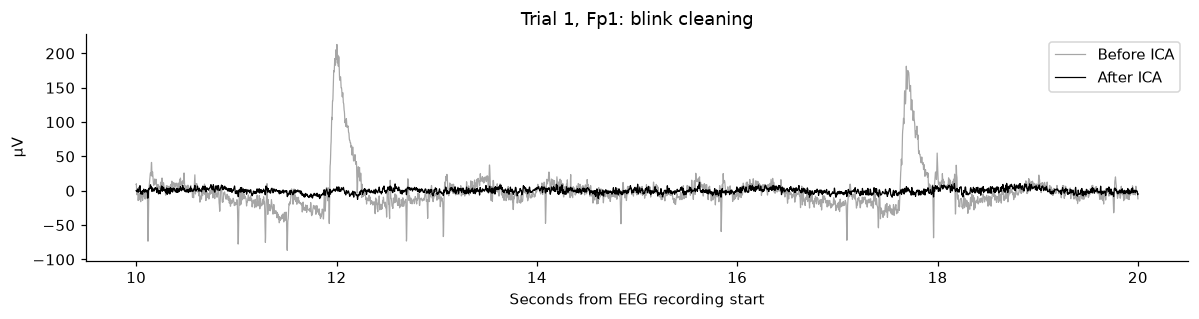

In [9]:
PREVIEW_TRIAL = 1
PREVIEW_CHANNEL = "Fp1"
START_S, END_S = 10, 20
fig, ax = plt.subplots(figsize=(11, 3))
for raw, label, color in [(referenced[PREVIEW_TRIAL], "Before ICA", "0.65"),
                          (cleaned[PREVIEW_TRIAL], "After ICA", "black")]:
    visible = (raw.times >= START_S) & (raw.times <= END_S)
    ax.plot(raw.times[visible], raw.get_data(picks=[PREVIEW_CHANNEL])[0, visible] * 1e6,
            color=color, linewidth=0.8, label=label)
ax.set(title=f"Trial {PREVIEW_TRIAL}, {PREVIEW_CHANNEL}: blink cleaning",
       xlabel="Seconds from EEG recording start", ylabel="µV")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Align and epoch

In [10]:
def make_epochs(raw, log, trial):
    sfreq = raw.info["sfreq"]
    eeg_start_ms = pd.Timestamp(raw.info["meas_date"]).timestamp() * 1000
    onset = (log["onset_epoch_ms"].to_numpy() - eeg_start_ms) / 1000 - CLOCK_OFFSET_S
    offset = (log["offset_epoch_ms"].to_numpy() - eeg_start_ms) / 1000 - CLOCK_OFFSET_S
    starts = np.ceil(onset * sfreq).astype(int)
    n_before, n_after = round(BASELINE_SECONDS * sfreq), round(EPOCH_SECONDS * sfreq)
    keep = (starts >= n_before) & (starts + n_after <= raw.n_times)
    keep &= (starts + n_after) / sfreq <= offset
    meta = log.loc[keep, ["seq", "stimulus_type", "complete"]].copy().reset_index(drop=True)
    meta = meta.rename(columns={"seq": "event_id", "complete": "log_complete"})
    codes = meta["stimulus_type"].map({"": 1, "other": 2, "trigger": 3}).to_numpy()
    meta["stimulus_type"] = meta["stimulus_type"].map({"": "blank", "other": "other word", "trigger": "activate"})
    meta["label"], meta["trial"] = (codes == 3).astype(int), trial
    meta["start_sample"] = starts[keep]
    meta["onset_in_eeg_s"], meta["offset_in_eeg_s"] = onset[keep], offset[keep]
    meta["start_s"], meta["end_s"] = starts[keep] / sfreq, (starts[keep] + n_after) / sfreq
    events = np.column_stack([starts[keep] + raw.first_samp, np.zeros(keep.sum(), int), codes])
    epochs = mne.Epochs(raw, events, {"blank": 1, "other": 2, "activate": 3},
                       tmin=-BASELINE_SECONDS, tmax=EPOCH_SECONDS - 1 / sfreq,
                       baseline=(-BASELINE_SECONDS, -1 / sfreq), metadata=meta,
                       preload=True, reject_by_annotation=True, verbose="error")
    assert len(epochs), f"No usable events in Trial {trial}."
    return epochs

In [11]:
epochs = {trial: make_epochs(cleaned[trial], logs[trial], trial) for trial in TRIALS}
X = np.concatenate([epochs[trial].get_data()[..., epochs[trial].times >= 0] for trial in TRIALS]) * 1e6
window_info = pd.concat([epochs[trial].metadata for trial in TRIALS], ignore_index=True)
y = window_info["label"].to_numpy()
window_info["split"] = np.where(window_info["trial"].isin(TRAIN_TRIALS), "Train",
                                np.where(window_info["trial"] == VALID_TRIAL, "Validation", "Test"))
train_mask = window_info["split"].eq("Train").to_numpy()
valid_mask = window_info["split"].eq("Validation").to_numpy()
test_mask = window_info["split"].eq("Test").to_numpy()
X_train, y_train = X[train_mask], y[train_mask]
X_valid, y_valid = X[valid_mask], y[valid_mask]
X_test, y_test = X[test_mask], y[test_mask]
assert X.shape[1:] == (len(channels), round(EPOCH_SECONDS * SAMPLE_RATE))
assert np.isfinite(X).all()
assert all(set(labels) == {0, 1} for labels in [y_train, y_valid, y_test])
assert (window_info["start_s"] >= window_info["onset_in_eeg_s"]).all()
assert (window_info["end_s"] <= window_info["offset_in_eeg_s"]).all()
assert all((np.diff(window_info.loc[window_info["trial"].eq(t), "start_s"]) >= EPOCH_SECONDS).all() for t in TRIALS)
counts = pd.crosstab([window_info["trial"], window_info["split"]], window_info["stimulus_type"])
counts["dropped events"] = [len(logs[trial]) - len(epochs[trial]) for trial, _ in counts.index]
display(counts)
print(f"Each example: {EPOCH_SECONDS:g} s, {len(channels)} channels, {X.shape[2]} samples in µV.")

Each example: 1 s, 21 channels, 500 samples in µV.


,stimulus_type,activate,blank,other word,dropped events
trial,split,,,,
1,Train,26,52,26,1
2,Train,24,49,24,0
3,Train,26,51,25,1
4,Validation,29,119,87,4
5,Test,30,114,90,9


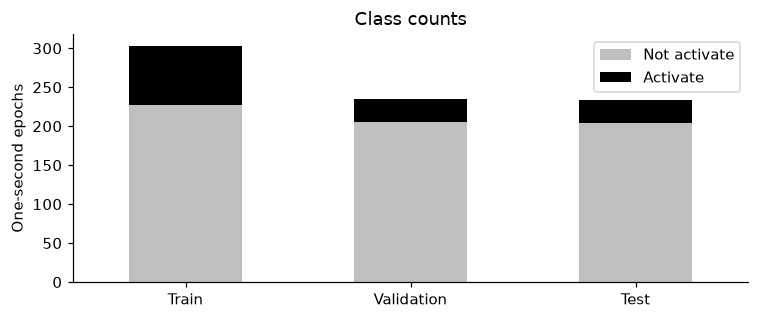

In [12]:
class_counts = pd.crosstab(window_info["split"], window_info["label"]).reindex(["Train", "Validation", "Test"])
class_counts.columns = ["Not activate", "Activate"]
ax = class_counts.plot.bar(stacked=True, color=["0.75", "black"], figsize=(7, 3), rot=0)
ax.set(xlabel="", ylabel="One-second epochs", title="Class counts")
plt.tight_layout()
plt.show()

## 6. Features and models

In [13]:
def bandpower(X, sfreq, bands):
    frequencies, power = welch(X, fs=sfreq, nperseg=min(X.shape[-1], int(sfreq)), axis=-1)
    features = [np.log(power[..., (frequencies >= low) & (frequencies < high)].mean(-1) + 1e-20)
                for low, high in bands]
    return np.stack(features, axis=-1).reshape(len(X), -1)


def time_bins(X, sfreq, bin_seconds):
    width = round(bin_seconds * sfreq)
    usable = X.shape[-1] // width * width
    return X[..., :usable].reshape(len(X), X.shape[1], -1, width).mean(-1).reshape(len(X), -1)


band_transform = FunctionTransformer(bandpower, kw_args={"sfreq": SAMPLE_RATE, "bands": BANDS})
erp_transform = FunctionTransformer(time_bins, kw_args={"sfreq": SAMPLE_RATE, "bin_seconds": ERP_BIN_SECONDS})

In [14]:
models = {
    "CSP + LDA": make_pipeline(CSP(n_components=6, reg="ledoit_wolf", log=True), LDA()),
    "Time bins + LDA": make_pipeline(clone(erp_transform), StandardScaler(), LDA(solver="lsqr", shrinkage="auto")),
    "Bandpower + LR": make_pipeline(clone(band_transform), StandardScaler(),
                                     LogisticRegression(max_iter=5000, class_weight="balanced")),
    "Bandpower + SVM": make_pipeline(clone(band_transform), StandardScaler(), SVC(class_weight="balanced")),
    "Bandpower + RF": make_pipeline(clone(band_transform),
                                    RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)),
    "Always not activate": make_pipeline(clone(band_transform), DummyClassifier(strategy="constant", constant=0)),
}
try:
    from pyriemann.estimation import Covariances
    from pyriemann.tangentspace import TangentSpace
except ImportError:
    print("Optional Riemann model skipped: pyriemann is not installed.")
else:
    models["Riemann + LR"] = make_pipeline(Covariances("oas"), TangentSpace(),
                                          LogisticRegression(max_iter=5000, class_weight="balanced"))
print("Models:", ", ".join(models))

Optional Riemann model skipped: pyriemann is not installed.
Models: CSP + LDA, Time bins + LDA, Bandpower + LR, Bandpower + SVM, Bandpower + RF, Always not activate


## 7. Train on Trials 1–3

In [15]:
fitted_models = {}
for name, model in models.items():
    fitted_models[name] = clone(model).fit(X_train, y_train)
    print(f"Trained {name}")

Trained CSP + LDA
Trained Time bins + LDA
Trained Bandpower + LR
Trained Bandpower + SVM
Trained Bandpower + RF
Trained Always not activate


## 8. Validate on Trial 4

In [16]:
def prediction_scores(model, features):
    if hasattr(model, "decision_function"):
        return model.decision_function(features)
    return model.predict_proba(features)[:, 1]


def evaluate(actual, predicted, scores):
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted),
        "Activate precision": precision_score(actual, predicted, zero_division=0),
        "Activate recall": recall_score(actual, predicted, zero_division=0),
        "Activate F1": f1_score(actual, predicted, zero_division=0),
        "ROC AUC": roc_auc_score(actual, scores),
        "Average precision": average_precision_score(actual, scores),
    }

Selected: Bandpower + RF


,Accuracy,Balanced accuracy,Activate precision,Activate recall,Activate F1,ROC AUC,Average precision
Model,,,,,,,
Bandpower + RF,0.949,0.912,0.758,0.862,0.806,0.980,0.885
Bandpower + SVM,0.949,0.882,0.793,0.793,0.793,0.983,0.901
Bandpower + LR,0.932,0.843,0.724,0.724,0.724,0.962,0.847
CSP + LDA,0.860,0.698,0.438,0.483,0.459,0.835,0.386
Time bins + LDA,0.885,0.594,0.600,0.207,0.308,0.812,0.458
Always not activate,0.877,0.500,0.000,0.000,0.000,0.500,0.123


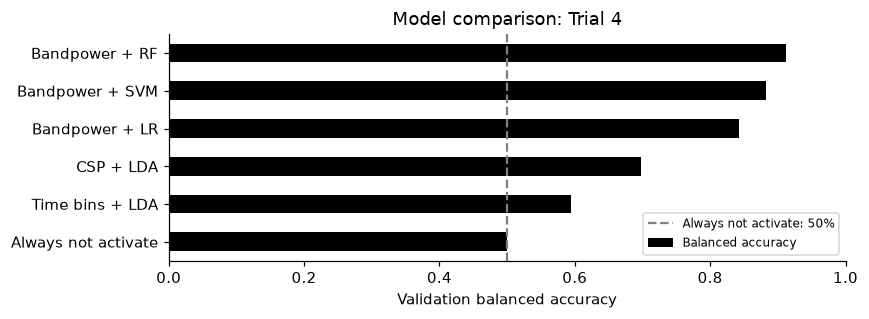

In [17]:
validation_rows = []
for name, model in fitted_models.items():
    metrics = evaluate(y_valid, model.predict(X_valid), prediction_scores(model, X_valid))
    validation_rows.append({"Model": name, **metrics})
validation_results = pd.DataFrame(validation_rows).set_index("Model").sort_values("Balanced accuracy", ascending=False, kind="stable")
best_name = validation_results.index[0]
best_model = fitted_models[best_name]
display(validation_results.style.format("{:.3f}"))
print("Selected:", best_name)
ax = validation_results["Balanced accuracy"].sort_values().plot.barh(color="black", figsize=(8, 3))
ax.axvline(0.5, color="gray", linestyle="--", label="Always not activate: 50%")
ax.set(xlim=(0, 1), xlabel="Validation balanced accuracy", ylabel="", title="Model comparison: Trial 4")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 9. Refit on Trials 1–4 and test on Trial 5
Keep the selected model settings fixed. Trial 5 was evaluated in the previous notebook too, so this is an exploratory comparison.

In [18]:
final_model = clone(best_model)
final_model.fit(np.vstack([X_train, X_valid]), np.concatenate([y_train, y_valid]))
test_predictions = final_model.predict(X_test)
test_scores = prediction_scores(final_model, X_test)
test_metrics = evaluate(y_test, test_predictions, test_scores)
baseline_metrics = evaluate(y_test, np.zeros_like(y_test), np.zeros_like(y_test, dtype=float))
comparison = pd.DataFrame({"Selected model": test_metrics, "Always not activate": baseline_metrics})
formatted = comparison.astype(object)
for metric in comparison.index:
    number_format = "{:.3f}" if metric in ["ROC AUC", "Average precision"] else "{:.1%}"
    formatted.loc[metric] = comparison.loc[metric].map(number_format.format)
display(formatted)
print(f"Detected {int(((y_test == 1) & (test_predictions == 1)).sum())} of {int(y_test.sum())} activate epochs.")
print(f"False activations: {int(((y_test == 0) & (test_predictions == 1)).sum())} of {int((y_test == 0).sum())} negative epochs.")

Detected 28 of 30 activate epochs.
False activations: 5 of 204 negative epochs.


,Selected model,Always not activate
Accuracy,97.0%,87.2%
Balanced accuracy,95.4%,50.0%
Activate precision,84.8%,0.0%
Activate recall,93.3%,0.0%
Activate F1,88.9%,0.0%
ROC AUC,0.982,0.500
Average precision,0.895,0.128


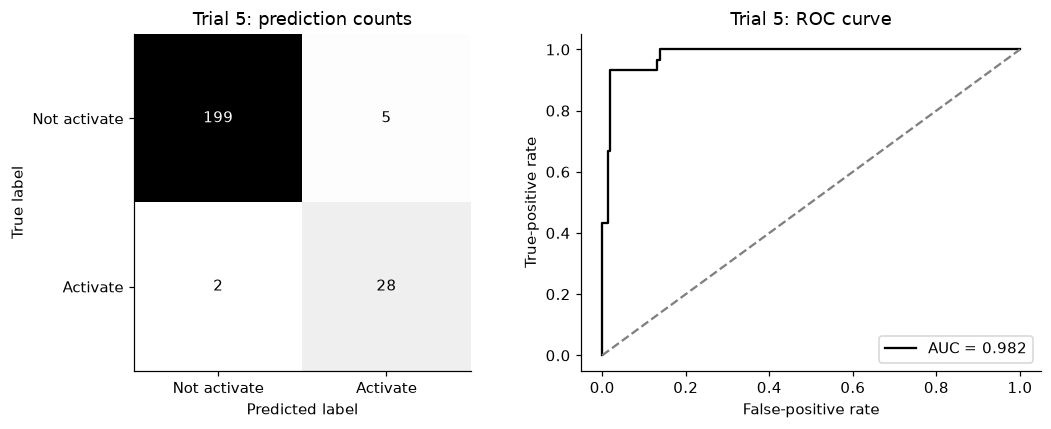

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, labels=[0, 1],
    display_labels=["Not activate", "Activate"], cmap="Greys", colorbar=False, ax=axes[0])
axes[0].set_title(f"Trial {TEST_TRIAL}: prediction counts")
false_positive_rate, true_positive_rate, _ = roc_curve(y_test, test_scores)
axes[1].plot(false_positive_rate, true_positive_rate, color="black", label=f"AUC = {test_metrics['ROC AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[1].set(title=f"Trial {TEST_TRIAL}: ROC curve", xlabel="False-positive rate", ylabel="True-positive rate")
axes[1].legend(loc="lower right")
fig.tight_layout()
plt.show()

In [20]:
prediction_table = window_info.loc[test_mask].reset_index(drop=True).copy()
prediction_table["predicted"] = test_predictions
prediction_table["score"] = test_scores
negative_epochs = prediction_table[prediction_table["label"] == 0]
false_activations = negative_epochs.groupby("stimulus_type")["predicted"].agg(epochs="size", false_activations="sum")
false_activations["false_activation_rate"] = false_activations["false_activations"] / false_activations["epochs"]
display(false_activations.style.format({"false_activation_rate": "{:.1%}"}))

,epochs,false_activations,false_activation_rate
stimulus_type,,,
blank,114,0,0.0%
other word,90,5,5.6%


## 10. Save

In [21]:
preprocessing_settings = {
    "clock_offset_s": CLOCK_OFFSET_S, "dropped_channels": DROP_CHANNELS,
    "montage": "colin27_1005", "notch_hz": np.arange(LINE_FREQ, raws[TRIALS[0]].info["sfreq"] / 2, LINE_FREQ).tolist(),
    "filter_method": "fir", "filter_phase": "zero", "bandpass_hz": BANDPASS,
    "sample_rate_hz": SAMPLE_RATE, "bad_channel_robust_z": BAD_Z, "flat_sd_volts": FLAT_SD,
    "interpolate_bads": True, "reference": "average", "ica_method": "fastica",
    "ica_fit_highpass_hz": 1.0, "ica_max_components": ICA_MAX_COMPONENTS,
    "ica_max_exclude": ICA_MAX_EXCLUDE, "ica_seed": 97,
    "cleaning_fit": "independent unsupervised cleaning per full recording, including validation and test",
    "epoch_seconds": EPOCH_SECONDS, "baseline_seconds": [-BASELINE_SECONDS, 0],
    "baseline_endpoint": "excludes onset", "epoch_policy": "one full post-onset epoch per event; ceil to next sample",
    "incomplete_event_policy": "include if a full epoch fits the actual recorded interval",
}

In [22]:
report = {
    "source_code": "neurotech_hackathon-main", "experiment": 2, "condition": "spoken",
    "train_trials": TRAIN_TRIALS, "validation_trial": VALID_TRIAL, "test_trial": TEST_TRIAL,
    "refit_trials": TRAIN_TRIALS + [VALID_TRIAL], "selected_model": best_name,
    "test_status": "previously evaluated trial; excluded from model selection in this run",
    "validation_balanced_accuracy": float(validation_results.loc[best_name, "Balanced accuracy"]),
    "train_epochs": len(y_train), "validation_epochs": len(y_valid), "test_epochs": len(y_test),
    "preprocessing": preprocessing_settings, "channels": channels, "feature_bands_hz": BANDS,
    "time_bin_seconds": ERP_BIN_SECONDS, "input_units": "microvolts", "input_shape": list(X.shape[1:]),
    "candidate_models": list(models), "selected_pipeline": str(final_model),
    "test_metrics": test_metrics, "always_not_activate": baseline_metrics,
    "confusion_matrix": confusion_matrix(y_test, test_predictions, labels=[0, 1]).tolist(),
    "false_activations": false_activations.reset_index().to_dict(orient="records"),
    "quality_checks": quality_table.reset_index().to_dict(orient="records"), "sources": sources,
    "notes": ["The +15.6 s correction is fixed and approximate; speech timing does not establish an exact clock offset.",
              "Epochs shortened from 2 s to 1 s to stay inside the labeled event.",
              "ICA uses frontal EEG channels as blink proxies.",
              "Spoken muscle activity may contribute; this does not establish thought-only detection.",
              "Baseline subtraction uses preceding activity; this is offline onset-aligned classification.",
              "Trial-wise splitting replaces shuffled folds; no binomial significance claim for balanced accuracy."],
}

In [23]:
OUTPUT.mkdir(parents=True, exist_ok=True)
for trial in TRIALS:
    cleaned[trial].save(OUTPUT / f"trial_{trial}_preprocessed_raw.fif", overwrite=True, verbose="error")
    icas[trial].save(OUTPUT / f"trial_{trial}_ica.fif", overwrite=True, verbose="error")
    epochs[trial].save(OUTPUT / f"trial_{trial}-epo.fif", overwrite=True, verbose="error")
quality_table.to_csv(OUTPUT / "preprocessing_qc.csv")
channel_report.to_csv(OUTPUT / "channel_checks.csv", index=False)
validation_results.to_csv(OUTPUT / "validation_results.csv")
prediction_table.to_csv(OUTPUT / "test_predictions.csv", index=False)
window_info.to_csv(OUTPUT / "epoch_split.csv", index=False)
np.savez_compressed(OUTPUT / "epochs.npz", X=X, y=y, trial=window_info["trial"].to_numpy(),
                    split=window_info["split"].to_numpy(dtype=str), channels=np.array(channels), sfreq=SAMPLE_RATE)
(OUTPUT / "metrics.json").write_text(json.dumps(report, indent=2) + "\n")
artifact = {"pipeline": final_model, "channels": channels, "input_shape": list(X.shape[1:]),
            "input_units": "microvolts", "preprocessing": preprocessing_settings,
            "feature_bands_hz": BANDS, "time_bin_seconds": ERP_BIN_SECONDS,
            "labels": {0: "not activate", 1: "activate"}}
with (OUTPUT / "activate_classifier.pkl").open("wb") as file:
    cloudpickle.dump(artifact, file)
with (OUTPUT / "activate_classifier.pkl").open("rb") as file:
    reloaded = cloudpickle.load(file)["pipeline"]
np.testing.assert_array_equal(reloaded.predict(X_test), test_predictions)
np.testing.assert_allclose(prediction_scores(reloaded, X_test), test_scores)
print(f"Saved results to {OUTPUT}. Reloaded-model predictions verified.")

Saved results to /Users/ajayvikram/Desktop/ML/neurotech/results/hackathon_pipeline. Reloaded-model predictions verified.
